# NYC Taxi Trip Duration: End-to-End ML Analysis

**Study period:** January to June 2026 | **Sources:** NYC TLC Yellow and Green taxi records

This single notebook covers data auditing, cleaning, exploratory analysis, leakage-safe feature screening, model experiments, and final evaluation for Yellow and Green taxi trip duration. DuckDB performs full-dataset aggregations so the raw records do not need to be loaded into memory as a single DataFrame.

### Research questions

1. How are trip durations distributed for Yellow and Green services?
2. How do pickup patterns vary by hour, weekday, month, and borough?
3. How do the services differ in data volume, data quality, and geographic coverage?
4. Which trip-start variables provide useful predictive signal without target or time leakage?

The analysis describes historical records. It does not estimate causal effects or provide live traffic conditions. Downstream prediction features should be limited to information available when a trip begins.


## 1. Setup and analysis conventions

The analysis retains trips with durations from 1 to 180 minutes, inclusive. Each pickup timestamp must fall within the month of its source file. Zone IDs 264 and 265 are excluded because they represent unknown or outside-city locations. Passenger-count nulls and zeros are measured and reported, not silently removed.


In [1]:
"""Scalable NYC TLC Yellow/Green taxi data audit, cleaning, and EDA."""


from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display


ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 33
MIN_DURATION_MINUTES = 1.0
MAX_DURATION_MINUTES = 180.0

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"yellow": "#D6A900", "green": "#168A62"}
con = duckdb.connect()
con.execute("SET threads TO 4")


def sql_path(path: Path) -> str:
    return str(path).replace("'", "''")


def read_glob(service: str) -> str:
    return sql_path(RAW / service / f"{service}_tripdata_2026-*.parquet")


## 2. Dataset inventory and schema

The inventory reports monthly file sizes and raw record counts, followed by the schema for each service. Yellow and Green files use different pickup and drop-off timestamp column names and contain some service-specific fields. The cleaning step standardizes the fields required for this analysis.


In [2]:
files = sorted((RAW / "yellow").glob("*.parquet")) + sorted(
    (RAW / "green").glob("*.parquet")
)
if not files:
    raise FileNotFoundError(f"No TLC Parquet files found beneath {RAW}")
file_audit = pd.DataFrame(
    [{"file": str(p.relative_to(ROOT)), "size_mb": p.stat().st_size / 1_000_000} for p in files]
)
display(file_audit)

for service in ("yellow", "green"):
    glob = read_glob(service)
    print(f"\n{service.title()} schema")
    display(con.execute(f"DESCRIBE SELECT * FROM read_parquet('{glob}')").df())

print("\nRaw records by service and source month")
raw_volume = con.execute(
    f"""
    SELECT 'yellow' AS taxi_type,
           regexp_extract(filename, '2026-([0-9]{{2}})', 1) AS source_month,
           count(*) AS rows
    FROM read_parquet('{read_glob('yellow')}', filename=true)
    GROUP BY 1, 2
    UNION ALL
    SELECT 'green', regexp_extract(filename, '2026-([0-9]{{2}})', 1), count(*)
    FROM read_parquet('{read_glob('green')}', filename=true)
    GROUP BY 1, 2
    ORDER BY source_month, taxi_type
    """
).df()
display(raw_volume.pivot(index="source_month", columns="taxi_type", values="rows"))


,file,size_mb
0,data/raw/yellow/yellow_tripdata_2026-01.parquet,64.165080
1,data/raw/yellow/yellow_tripdata_2026-02.parquet,58.683353
2,data/raw/yellow/yellow_tripdata_2026-03.parquet,67.891249
3,data/raw/yellow/yellow_tripdata_2026-04.parquet,64.818115
4,data/raw/yellow/yellow_tripdata_2026-05.parquet,69.699174
5,data/raw/yellow/yellow_tripdata_2026-06.parquet,65.465637
6,data/raw/green/green_tripdata_2026-01.parquet,0.991656
7,data/raw/green/green_tripdata_2026-02.parquet,0.920753
8,data/raw/green/green_tripdata_2026-03.parquet,1.082530
9,data/raw/green/green_tripdata_2026-04.parquet,1.075896



Yellow schema


,column_name,column_type,null,key,default,extra
0,VendorID,INTEGER,YES,None,None,None
1,tpep_pickup_datetime,TIMESTAMP,YES,None,None,None
2,tpep_dropoff_datetime,TIMESTAMP,YES,None,None,None
3,passenger_count,BIGINT,YES,None,None,None
4,trip_distance,DOUBLE,YES,None,None,None
5,RatecodeID,BIGINT,YES,None,None,None
6,store_and_fwd_flag,VARCHAR,YES,None,None,None
7,PULocationID,INTEGER,YES,None,None,None
8,DOLocationID,INTEGER,YES,None,None,None
9,payment_type,BIGINT,YES,None,None,None



Green schema


,column_name,column_type,null,key,default,extra
0,VendorID,INTEGER,YES,None,None,None
1,lpep_pickup_datetime,TIMESTAMP,YES,None,None,None
2,lpep_dropoff_datetime,TIMESTAMP,YES,None,None,None
3,store_and_fwd_flag,VARCHAR,YES,None,None,None
4,RatecodeID,BIGINT,YES,None,None,None
5,PULocationID,INTEGER,YES,None,None,None
6,DOLocationID,INTEGER,YES,None,None,None
7,passenger_count,BIGINT,YES,None,None,None
8,trip_distance,DOUBLE,YES,None,None,None
9,fare_amount,DOUBLE,YES,None,None,None



Raw records by service and source month


taxi_type,green,yellow
source_month,,
01,40272,3724889
02,37373,3399866
03,44208,3952451
04,44238,3831240
05,44921,4090836
06,44163,3837248


## 3. Cleaning rules and retained-row audit

Exclusion criteria are applied sequentially so the audit reports a reconciled row count after each step: valid timestamps, pickup month matching the source file, duration within the analysis window, and valid known pickup and drop-off zones. The 1 to 180 minute duration range is an analytical choice. Review the duration distribution and test alternative thresholds before treating it as a general validity rule.


In [3]:
cleaning_counts = []
clean_views = []
for service, pickup_col, dropoff_col in (
    ("yellow", "tpep_pickup_datetime", "tpep_dropoff_datetime"),
    ("green", "lpep_pickup_datetime", "lpep_dropoff_datetime"),
):
    glob = read_glob(service)
    normalized = f"normalized_{service}"
    con.execute(
        f"""
        CREATE OR REPLACE TEMP VIEW {normalized} AS
        SELECT *,
          try_cast({pickup_col} AS TIMESTAMP) AS pickup_datetime,
          try_cast({dropoff_col} AS TIMESTAMP) AS dropoff_datetime,
          try_cast(PULocationID AS INTEGER) AS pu_zone,
          try_cast(DOLocationID AS INTEGER) AS do_zone,
          regexp_extract(filename, '2026-([0-9]{{2}})', 1) AS source_month,
          date_diff('second', try_cast({pickup_col} AS TIMESTAMP),
                              try_cast({dropoff_col} AS TIMESTAMP)) / 60.0 AS duration_min
        FROM read_parquet('{glob}', filename=true)
        """
    )
    stats = con.execute(
        f"""SELECT count(*) AS raw_rows,
          count(*) FILTER (WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL) AS after_timestamps,
          count(*) FILTER (WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL
            AND strftime(pickup_datetime, '%m') = source_month) AS after_source_month,
          count(*) FILTER (WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL
            AND strftime(pickup_datetime, '%m') = source_month
            AND duration_min BETWEEN {MIN_DURATION_MINUTES} AND {MAX_DURATION_MINUTES}) AS after_duration,
          count(*) FILTER (WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL
            AND strftime(pickup_datetime, '%m') = source_month
            AND duration_min BETWEEN {MIN_DURATION_MINUTES} AND {MAX_DURATION_MINUTES}
            AND pu_zone IS NOT NULL AND do_zone IS NOT NULL
            AND pu_zone NOT IN (264,265) AND do_zone NOT IN (264,265)) AS retained_rows
          FROM {normalized}"""
    ).fetchone()
    raw_count, after_timestamps, after_month, after_duration, final_count = stats
    cleaning_counts.append(
        {"taxi_type": service, "raw_rows": raw_count,
         "dropped_invalid_timestamp": raw_count - after_timestamps,
         "after_timestamps": after_timestamps,
         "dropped_pickup_outside_source_month": after_timestamps - after_month,
         "after_source_month": after_month,
         "dropped_duration_outside_1_180_min": after_month - after_duration,
         "after_duration": after_duration,
         "dropped_missing_or_unknown_zone": after_duration - final_count,
         "retained_rows": final_count,
         "retained_pct": 100 * final_count / raw_count}
    )
    clean_view = f"clean_{service}"
    con.execute(
        f"""
        CREATE OR REPLACE TEMP VIEW {clean_view} AS
        SELECT '{service}' AS taxi_type, pickup_datetime, dropoff_datetime,
               CAST(duration_min AS DOUBLE) AS trip_duration_minutes,
               pu_zone AS PULocationID, do_zone AS DOLocationID,
               try_cast(passenger_count AS DOUBLE) AS passenger_count,
               CAST(source_month AS INTEGER) AS month
        FROM {normalized}
        WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL
          AND duration_min BETWEEN {MIN_DURATION_MINUTES} AND {MAX_DURATION_MINUTES}
          AND strftime(pickup_datetime, '%m') = source_month
          AND pu_zone IS NOT NULL AND do_zone IS NOT NULL
          AND pu_zone NOT IN (264,265) AND do_zone NOT IN (264,265)
        """
    )
    clean_views.append(clean_view)
    output = PROCESSED / f"{service}_cleaned_2026H1.parquet"
    con.execute(f"COPY {clean_view} TO '{sql_path(output)}' (FORMAT PARQUET, COMPRESSION ZSTD)")

cleaning_audit = pd.DataFrame(cleaning_counts)
display(cleaning_audit)
con.execute(
    f"COPY (SELECT * FROM clean_yellow UNION ALL SELECT * FROM clean_green) "
    f"TO '{sql_path(PROCESSED / 'taxi_cleaned_2026H1.parquet')}' (FORMAT PARQUET, COMPRESSION ZSTD)"
)


,taxi_type,raw_rows,dropped_invalid_timestamp,after_timestamps,dropped_pickup_outside_source_month,after_source_month,dropped_duration_outside_1_180_min,after_duration,dropped_missing_or_unknown_zone,retained_rows,retained_pct
0,yellow,22836530,0,22836530,85,22836445,527942,22308503,135076,22173427,97.096306
1,green,255175,0,255175,68,255107,9184,245923,2394,243529,95.436073


## 4. Missing values, duplicate records, and duration outliers

This audit examines the normalized source records before the main duration and zone exclusions. Missingness is measured across all available months, while duration diagnostics use parseable trips whose pickup month matches the source file. Duplicate detection uses an explicit trip-key candidate and reports repeated groups without automatically deleting them. Matching records can be legitimate repeated trips, so they require interpretation rather than blind deduplication.

### Initial observations from the audited files

Passenger count is the main field with missing values among the audited inputs: it is missing in **25.51% of raw Yellow records** and **14.12% of raw Green records**. Zero counts are separate and less common. The selected trip key identifies **134,497 Yellow groups** and **711 Green groups** with repeated records. These are candidates for investigation, not records removed from the analysis.

The duration distribution has a long tail. Before applying the 1-to-180-minute cleaning window, **8,246 Yellow records (0.036%)** and **1,047 Green records (0.410%)** exceed 180 minutes. Negative durations are rare, but zero-duration and sub-minute records are more frequent. Tukey-fence flags are reported as a statistical tail diagnostic; they are not treated as invalid trips automatically.

taxi_type,green,yellow
field,,
dropoff_timestamp_invalid,0.00,0.00
dropoff_zone_missing,0.00,0.00
fare_amount_missing,0.00,0.00
passenger_count_missing,14.12,25.51
passenger_count_zero,1.34,0.33
pickup_timestamp_invalid,0.00,0.00
pickup_zone_missing,0.00,0.00
total_amount_missing,0.00,0.00
trip_distance_missing,0.00,0.00


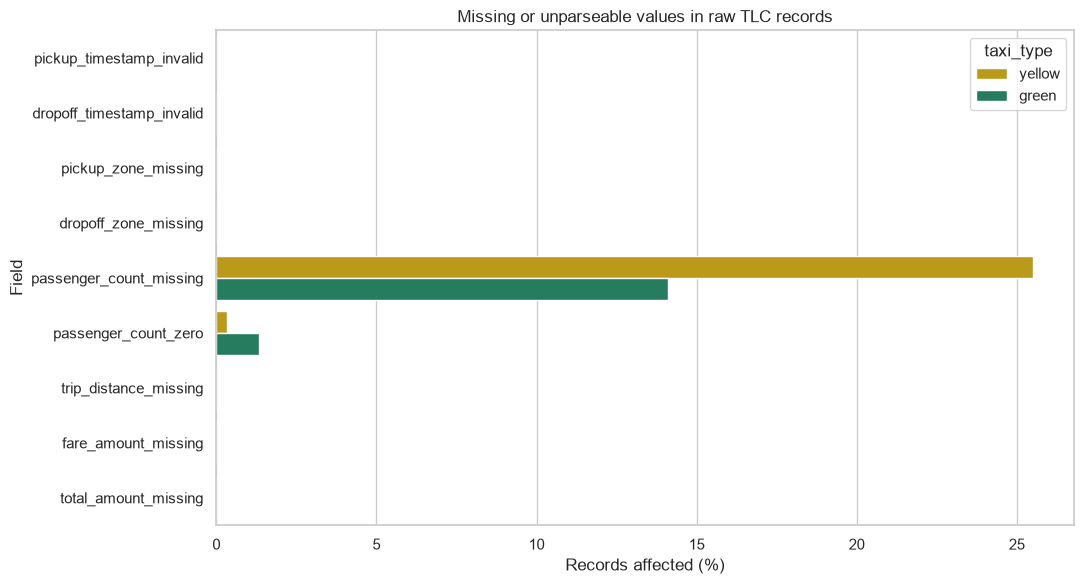

,taxi_type,duplicate_key_groups,rows_in_duplicate_groups,repeated_rows_beyond_first
0,yellow,134497,269006.0,134509.0
1,green,711,1422.0,711.0


,taxi_type,timestamp_valid_rows,q1_min,median_min,q3_min,p90_min,p99_min,p99_9_min,max_min,negative_duration_rows,zero_duration_rows,below_one_minute_rows,above_180_minute_rows,above_12_hour_rows,tukey_upper_fence_min,above_tukey_upper_fence_rows,negative_duration_pct,above_180_minute_pct
0,yellow,22836445,8.300,13.867,22.100,33.667,73.867,122.750,9983.933,6,286175,235047,8246,4651,42.800,1274867,0.000,0.036
1,green,255107,8.333,13.100,20.517,33.000,85.166,1407.641,2456.367,5,182,8000,1047,761,38.792,18071,0.002,0.410


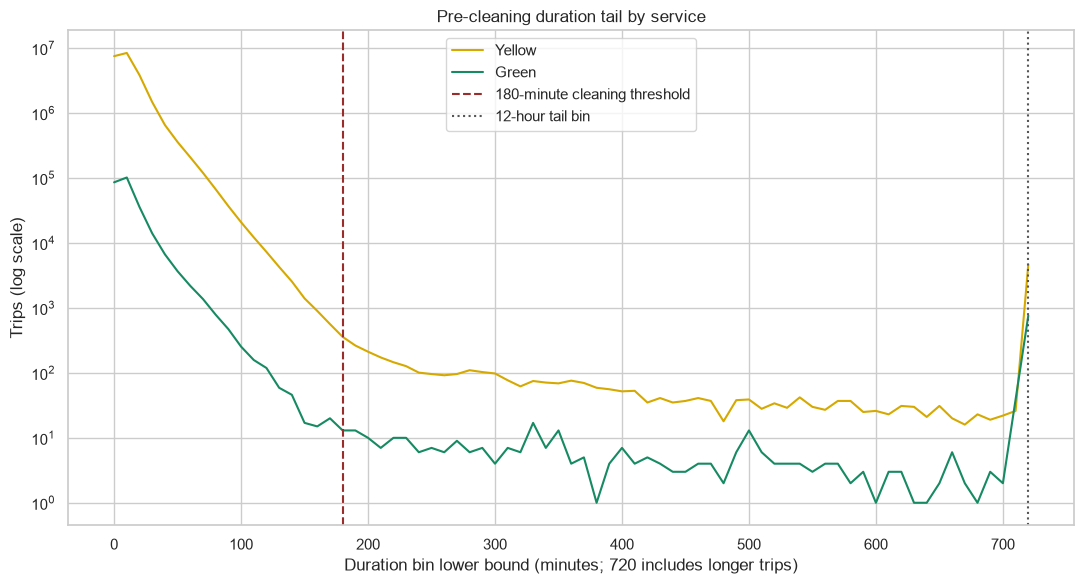

In [4]:
missingness_rows = []
for service in ("yellow", "green"):
    view = f"normalized_{service}"
    audit = con.execute(f"""
        SELECT count(*) AS raw_rows,
          count(*) FILTER (WHERE pickup_datetime IS NULL) AS pickup_timestamp_invalid,
          count(*) FILTER (WHERE dropoff_datetime IS NULL) AS dropoff_timestamp_invalid,
          count(*) FILTER (WHERE pu_zone IS NULL) AS pickup_zone_missing,
          count(*) FILTER (WHERE do_zone IS NULL) AS dropoff_zone_missing,
          count(*) FILTER (WHERE try_cast(passenger_count AS DOUBLE) IS NULL) AS passenger_count_missing,
          count(*) FILTER (WHERE try_cast(passenger_count AS DOUBLE) = 0) AS passenger_count_zero,
          count(*) FILTER (WHERE try_cast(trip_distance AS DOUBLE) IS NULL) AS trip_distance_missing,
          count(*) FILTER (WHERE try_cast(fare_amount AS DOUBLE) IS NULL) AS fare_amount_missing,
          count(*) FILTER (WHERE try_cast(total_amount AS DOUBLE) IS NULL) AS total_amount_missing
        FROM {view}
    """).df().iloc[0]
    total = int(audit.raw_rows)
    for field in audit.index.drop("raw_rows"):
        missingness_rows.append({"taxi_type": service, "field": field,
                                "records": int(audit[field]),
                                "percent_of_raw": 100 * audit[field] / total})
missingness_audit = pd.DataFrame(missingness_rows)
display(missingness_audit.pivot(index="field", columns="taxi_type", values="percent_of_raw").round(2))

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=missingness_audit, x="percent_of_raw", y="field", hue="taxi_type", palette=COLORS, ax=ax)
ax.set(title="Missing or unparseable values in raw TLC records", xlabel="Records affected (%)", ylabel="Field")
fig.tight_layout()
fig.savefig(FIGURES / "eda_missingness_audit.png", dpi=180, bbox_inches="tight")
plt.show()

duplicate_rows = []
for service in ("yellow", "green"):
    view = f"normalized_{service}"
    duplicate_rows.append(con.execute(f"""
        WITH eligible AS (
          SELECT pickup_datetime, dropoff_datetime, pu_zone, do_zone,
                 try_cast(passenger_count AS DOUBLE) AS passenger_count, duration_min
          FROM {view}
          WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL
            AND strftime(pickup_datetime, '%m') = source_month
        ), duplicate_groups AS (
          SELECT pickup_datetime, dropoff_datetime, pu_zone, do_zone, passenger_count, duration_min,
                 count(*) AS group_rows
          FROM eligible
          GROUP BY ALL
          HAVING count(*) > 1
        )
        SELECT '{service}' AS taxi_type, count(*) AS duplicate_key_groups,
               coalesce(sum(group_rows), 0) AS rows_in_duplicate_groups,
               coalesce(sum(group_rows - 1), 0) AS repeated_rows_beyond_first
        FROM duplicate_groups
    """).df())
duplicate_audit = pd.concat(duplicate_rows, ignore_index=True)
display(duplicate_audit)

duration_audits = []
duration_histograms = []
for service in ("yellow", "green"):
    view = f"normalized_{service}"
    duration_audits.append(con.execute(f"""
        WITH valid AS (
          SELECT duration_min FROM {view}
          WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL
            AND strftime(pickup_datetime, '%m') = source_month AND duration_min IS NOT NULL
        ), bounds AS (
          SELECT count(*) AS timestamp_valid_rows,
                 quantile_cont(duration_min, 0.25) AS q1_min,
                 quantile_cont(duration_min, 0.50) AS median_min,
                 quantile_cont(duration_min, 0.75) AS q3_min,
                 quantile_cont(duration_min, 0.90) AS p90_min,
                 quantile_cont(duration_min, 0.99) AS p99_min,
                 quantile_cont(duration_min, 0.999) AS p99_9_min,
                 max(duration_min) AS max_min,
                 count(*) FILTER (WHERE duration_min < 0) AS negative_duration_rows,
                 count(*) FILTER (WHERE duration_min = 0) AS zero_duration_rows,
                 count(*) FILTER (WHERE duration_min BETWEEN 0 AND 1 AND duration_min <> 0) AS below_one_minute_rows,
                 count(*) FILTER (WHERE duration_min > 180) AS above_180_minute_rows,
                 count(*) FILTER (WHERE duration_min > 720) AS above_12_hour_rows
          FROM valid
        ), flagged AS (
          SELECT *, q3_min + 1.5 * (q3_min - q1_min) AS tukey_upper_fence_min FROM bounds
        )
        SELECT '{service}' AS taxi_type, *,
          (SELECT count(*) FROM valid, flagged WHERE duration_min > tukey_upper_fence_min) AS above_tukey_upper_fence_rows,
          100.0 * negative_duration_rows / nullif(timestamp_valid_rows, 0) AS negative_duration_pct,
          100.0 * above_180_minute_rows / nullif(timestamp_valid_rows, 0) AS above_180_minute_pct
        FROM flagged
    """).df())
    duration_histograms.append(con.execute(f"""
        SELECT '{service}' AS taxi_type,
               CASE WHEN duration_min > 720 THEN 720 ELSE floor(duration_min / 10) * 10 END AS bin_lower_min,
               count(*) AS trips
        FROM {view}
        WHERE pickup_datetime IS NOT NULL AND dropoff_datetime IS NOT NULL
          AND strftime(pickup_datetime, '%m') = source_month AND duration_min >= 0
        GROUP BY 1, 2 ORDER BY 2
    """).df())
outlier_audit = pd.concat(duration_audits, ignore_index=True)
duration_histogram_raw = pd.concat(duration_histograms, ignore_index=True)
display(outlier_audit.round(3))

fig, ax = plt.subplots(figsize=(11, 6))
for service in ("yellow", "green"):
    data = duration_histogram_raw.query("taxi_type == @service")
    ax.plot(data.bin_lower_min, data.trips, label=service.title(), color=COLORS[service])
ax.axvline(180, color="#9B2C2C", linestyle="--", label="180-minute cleaning threshold")
ax.axvline(720, color="#555555", linestyle=":", label="12-hour tail bin")
ax.set_yscale("log")
ax.set(title="Pre-cleaning duration tail by service", xlabel="Duration bin lower bound (minutes; 720 includes longer trips)", ylabel="Trips (log scale)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "eda_duration_outlier_audit.png", dpi=180, bbox_inches="tight")
plt.show()


## 5. Input quality: passenger count

Passenger count may be useful for prediction, but missing and zero values may reflect distinct reporting states. The table reports their prevalence by service. Exclude this feature from an initial model or handle missingness explicitly; do not assume that a missing value means zero passengers.


In [5]:
passenger_quality = con.execute(
    """
    SELECT taxi_type, count(*) AS trips,
      count(*) FILTER (WHERE passenger_count IS NULL) AS missing_passenger_count,
      count(*) FILTER (WHERE passenger_count = 0) AS zero_passenger_count,
      round(100.0 * count(*) FILTER (WHERE passenger_count IS NULL OR passenger_count = 0) / count(*), 2)
        AS missing_or_zero_pct
    FROM (SELECT * FROM clean_yellow UNION ALL SELECT * FROM clean_green)
    GROUP BY taxi_type ORDER BY taxi_type
    """
).df()
display(passenger_quality)


,taxi_type,trips,missing_passenger_count,zero_passenger_count,missing_or_zero_pct
0,green,243529,35764,2883,15.87
1,yellow,22173427,5792624,70996,26.44


## 6. Trip duration and temporal summaries

Trip durations have a long upper tail. Report medians and upper quantiles alongside means. Hourly and weekday comparisons use each service's share of its own trips, which makes temporal patterns comparable despite the large difference in fleet volume.


In [6]:
con.execute(
    f"""CREATE OR REPLACE TEMP VIEW all_clean AS
    SELECT * FROM clean_yellow UNION ALL SELECT * FROM clean_green"""
)
duration_summary = con.execute(
    """SELECT taxi_type, count(*) AS trips,
       round(avg(trip_duration_minutes), 2) AS mean_min,
       round(median(trip_duration_minutes), 2) AS median_min,
       round(quantile_cont(trip_duration_minutes, 0.90), 2) AS p90_min,
       round(quantile_cont(trip_duration_minutes, 0.99), 2) AS p99_min
       FROM all_clean GROUP BY taxi_type ORDER BY taxi_type"""
).df()
display(duration_summary)

duration_hist = con.execute(
    """SELECT taxi_type, least(179, floor(trip_duration_minutes / 5) * 5) AS bin_min,
       count(*) AS trips FROM all_clean GROUP BY 1,2 ORDER BY 2,1"""
).df()


,taxi_type,trips,mean_min,median_min,p90_min,p99_min
0,green,243529,17.25,13.37,32.63,75.13
1,yellow,22173427,17.78,14.10,33.68,73.07


In [7]:
monthly = con.execute(
    "SELECT taxi_type, month, count(*) AS trips FROM all_clean GROUP BY 1,2 ORDER BY 2,1"
).df()
hourly = con.execute(
    """SELECT taxi_type, hour(pickup_datetime) AS hour,
       count(*) AS trips, median(trip_duration_minutes) AS median_duration
       FROM all_clean GROUP BY 1,2 ORDER BY 2,1"""
).df()
weekday = con.execute(
    """SELECT taxi_type, dayofweek(pickup_datetime) AS weekday,
       count(*) AS trips, median(trip_duration_minutes) AS median_duration
       FROM all_clean GROUP BY 1,2 ORDER BY 2,1"""
).df()


### 6.1 Geography and service footprint

Pickup borough and zone shares describe where each service operates. These differences are relevant to model design because a combined model may primarily reflect Yellow's larger, Manhattan-concentrated sample. Evaluate performance by service and geography.


In [8]:
borough = con.execute(
    f"""SELECT c.taxi_type, coalesce(z.Borough, 'Unknown') AS borough, count(*) AS trips
       FROM all_clean c LEFT JOIN read_csv_auto('{sql_path(RAW / 'taxi_zone_lookup.csv')}') z
       ON c.PULocationID = z.LocationID
       GROUP BY 1,2 ORDER BY 1,3 DESC"""
).df()
top_zones = con.execute(
    f"""SELECT c.taxi_type, c.PULocationID, coalesce(z.Zone, 'Unknown') AS zone,
       coalesce(z.Borough, 'Unknown') AS borough, count(*) AS trips,
       100.0 * count(*) / sum(count(*)) OVER (PARTITION BY c.taxi_type) AS service_share_pct
       FROM all_clean c LEFT JOIN read_csv_auto('{sql_path(RAW / 'taxi_zone_lookup.csv')}') z
       ON c.PULocationID = z.LocationID
       GROUP BY 1,2,3,4
       QUALIFY row_number() OVER (PARTITION BY c.taxi_type ORDER BY count(*) DESC) <= 10
       ORDER BY 1,5 DESC"""
).df()


## 7. Figures and visual interpretation

The first figure presents the duration distribution, median duration by service, pickup share by hour, and median duration by pickup hour. A logarithmic scale is used for trip counts so the duration tail and both services remain visible.


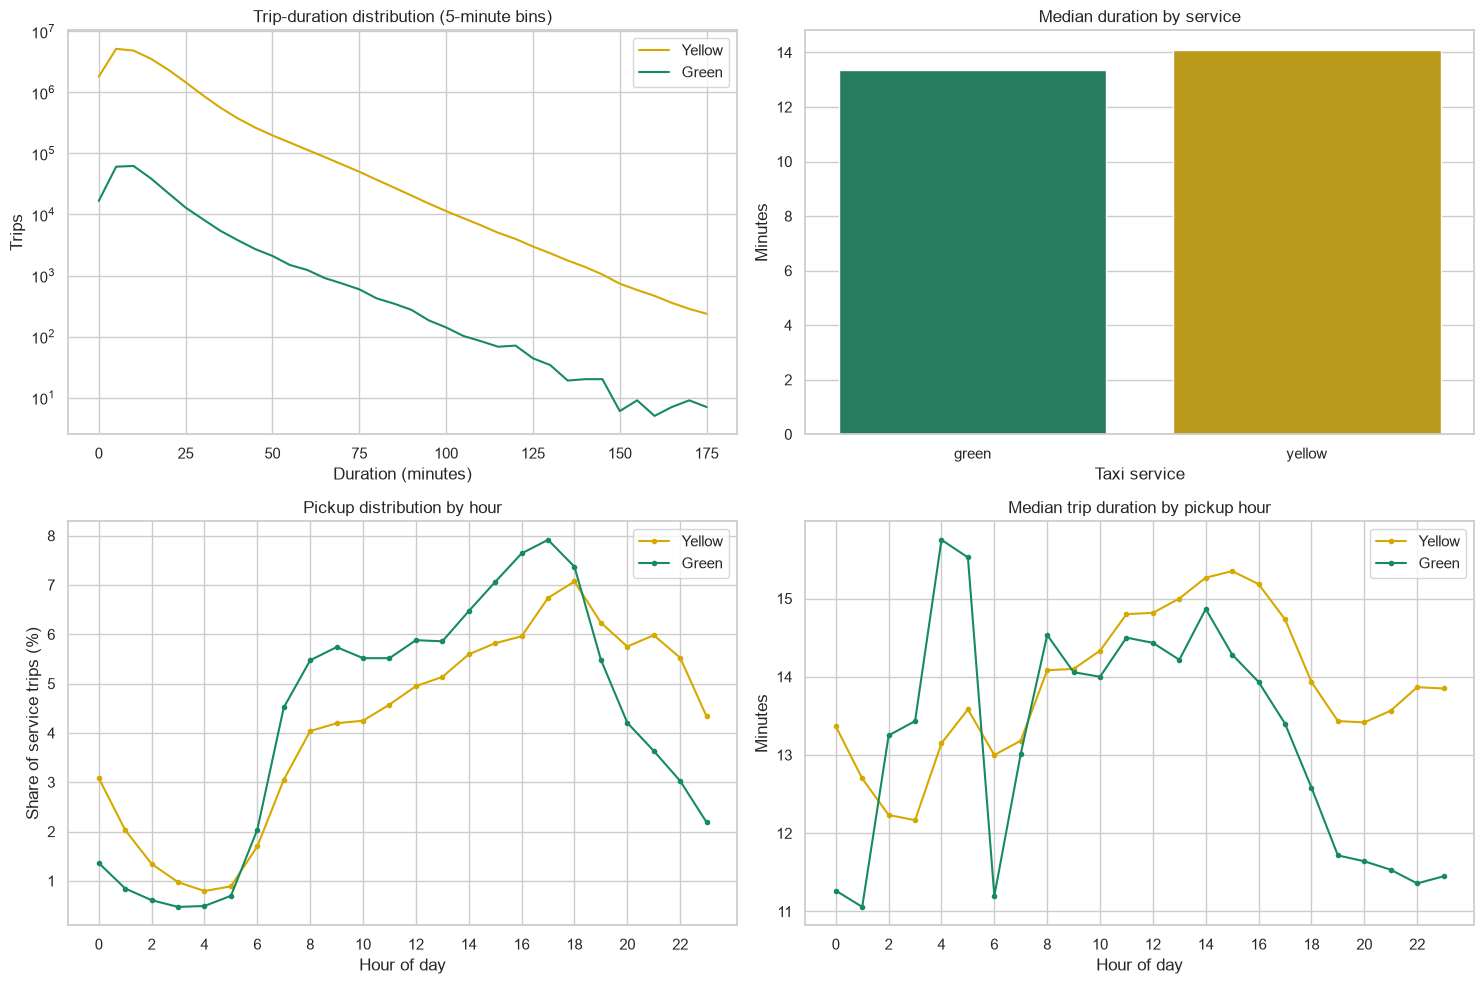

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for service in ("yellow", "green"):
    data = duration_hist[duration_hist.taxi_type == service]
    axes[0, 0].plot(data.bin_min, data.trips, label=service.title(), color=COLORS[service])
axes[0, 0].set(title="Trip-duration distribution (5-minute bins)", xlabel="Duration (minutes)", ylabel="Trips")
axes[0, 0].set_yscale("log")
axes[0, 0].legend()
sns.barplot(data=duration_summary, x="taxi_type", y="median_min", hue="taxi_type",
            palette=COLORS, legend=False, ax=axes[0, 1])
axes[0, 1].set(title="Median duration by service", xlabel="Taxi service", ylabel="Minutes")
for service in ("yellow", "green"):
    data = hourly[hourly.taxi_type == service]
    axes[1, 0].plot(data.hour, 100 * data.trips / data.trips.sum(), marker="o", ms=3,
                    label=service.title(), color=COLORS[service])
axes[1, 0].set(title="Pickup distribution by hour", xlabel="Hour of day", ylabel="Share of service trips (%)", xticks=range(0,24,2))
axes[1, 0].legend()
for service in ("yellow", "green"):
    data = hourly[hourly.taxi_type == service]
    axes[1, 1].plot(data.hour, data.median_duration, marker="o", ms=3,
                    label=service.title(), color=COLORS[service])
axes[1, 1].set(title="Median trip duration by pickup hour", xlabel="Hour of day", ylabel="Minutes", xticks=range(0,24,2))
axes[1, 1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "eda_duration_and_hourly_patterns.png", dpi=180, bbox_inches="tight")
plt.show()


### 7.1 Weekday patterns

The first panel compares the weekday distribution within each service. The second compares median trip duration by weekday. These differences may reflect trip purpose, route composition, and congestion; this descriptive analysis does not isolate their individual effects.


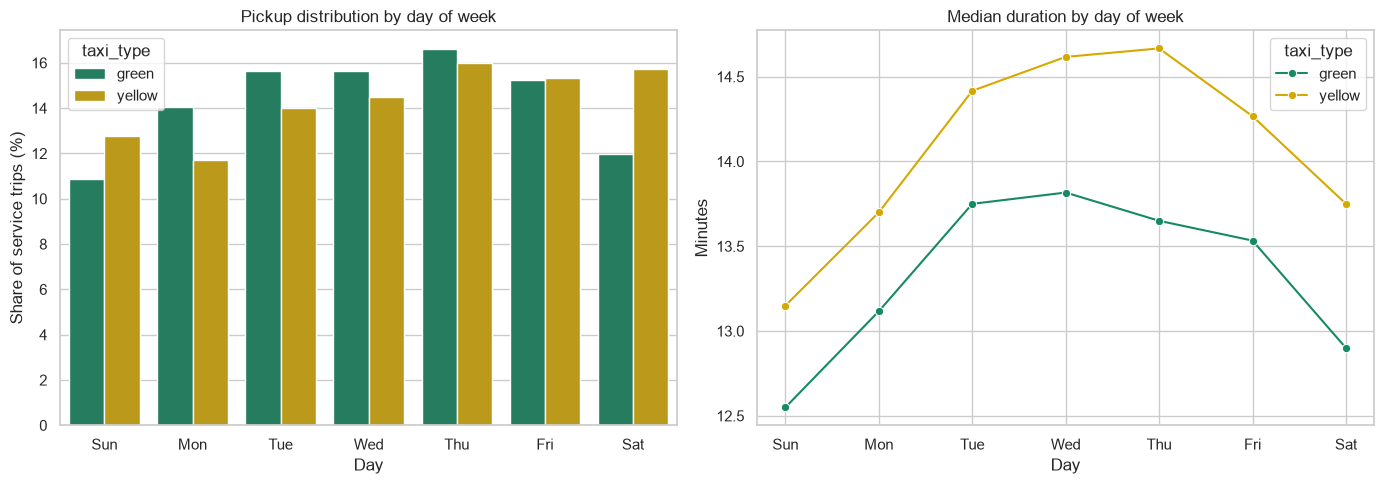

In [10]:
weekday_labels =  {0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"}
weekday["weekday_name"] = weekday.weekday.map(weekday_labels)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=weekday.assign(service_share=lambda d: 100 * d.trips / d.groupby("taxi_type").trips.transform("sum")),
            x="weekday_name", y="service_share", hue="taxi_type", palette=COLORS, ax=axes[0])
axes[0].set(title="Pickup distribution by day of week", xlabel="Day", ylabel="Share of service trips (%)")
sns.lineplot(data=weekday, x="weekday_name", y="median_duration", hue="taxi_type",
             palette=COLORS, marker="o", ax=axes[1])
axes[1].set(title="Median duration by day of week", xlabel="Day", ylabel="Minutes")
fig.tight_layout()
fig.savefig(FIGURES / "eda_weekday_patterns.png", dpi=180, bbox_inches="tight")
plt.show()


### 7.2 Monthly and borough patterns

Monthly trip counts are normalized within each service to support comparison despite the fleet-size difference. Borough percentages describe the pickup composition of each service. They do not measure service quality or total market coverage.


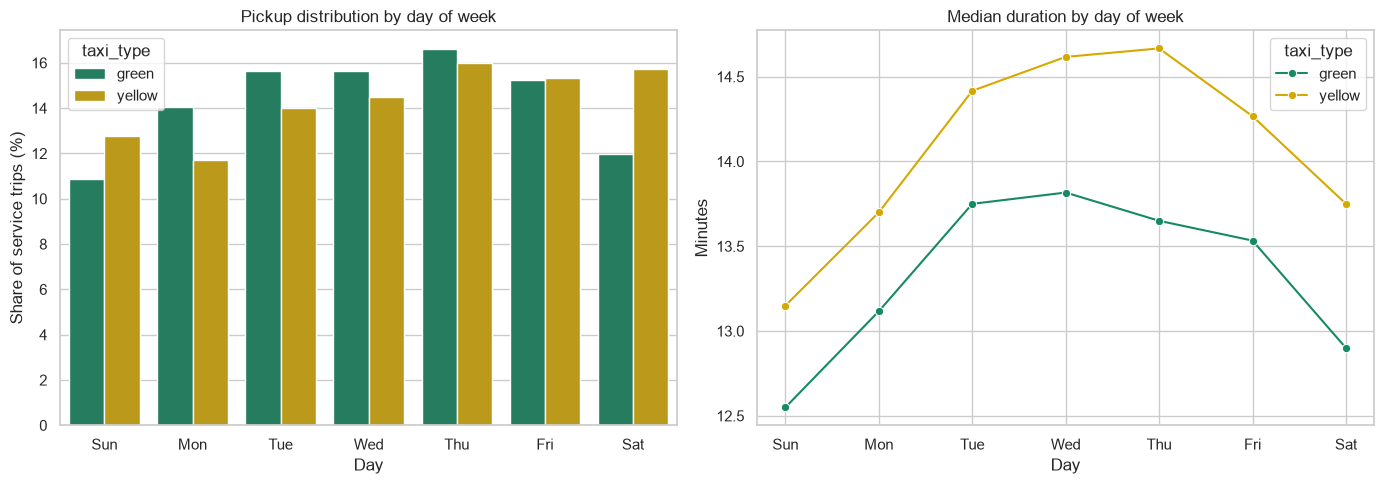

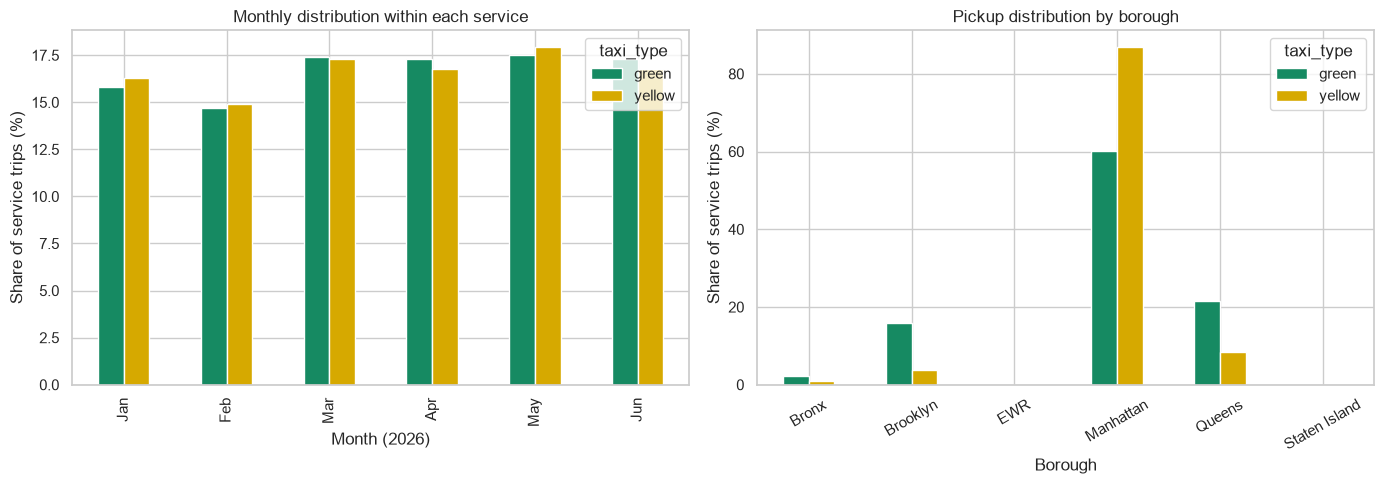

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=weekday.assign(service_share=lambda d: 100 * d.trips / d.groupby("taxi_type").trips.transform("sum")),
            x="weekday_name", y="service_share", hue="taxi_type", palette=COLORS, ax=axes[0])
axes[0].set(title="Pickup distribution by day of week", xlabel="Day", ylabel="Share of service trips (%)")
sns.lineplot(data=weekday, x="weekday_name", y="median_duration", hue="taxi_type",
             palette=COLORS, marker="o", ax=axes[1])
axes[1].set(title="Median duration by day of week", xlabel="Day", ylabel="Minutes")
fig.tight_layout()
fig.savefig(FIGURES / "eda_weekday_patterns.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
monthly_pivot = monthly.pivot(index="month", columns="taxi_type", values="trips").fillna(0)
monthly_share = monthly_pivot.div(monthly_pivot.sum(axis=0), axis=1) * 100
monthly_share.plot(kind="bar", color=[COLORS[c] for c in monthly_share.columns], ax=axes[0])
axes[0].set(title="Monthly distribution within each service", xlabel="Month (2026)", ylabel="Share of service trips (%)", xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun"])
borough_share = borough.assign(share=lambda d: d.trips / d.groupby("taxi_type").trips.transform("sum") * 100)
borough_plot = borough_share.pivot(index="borough", columns="taxi_type", values="share").fillna(0)
borough_plot.plot(kind="bar", color=[COLORS[c] for c in borough_plot.columns], ax=axes[1])
axes[1].set(title="Pickup distribution by borough", xlabel="Borough", ylabel="Share of service trips (%)")
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIGURES / "eda_monthly_volume_and_boroughs.png", dpi=180, bbox_inches="tight")
plt.show()


### 7.3 Most frequent pickup zones

The chart reports each top pickup zone as a percentage of that service's cleaned trips. This highlights geographic concentration without allowing Yellow's larger sample to dominate the comparison.


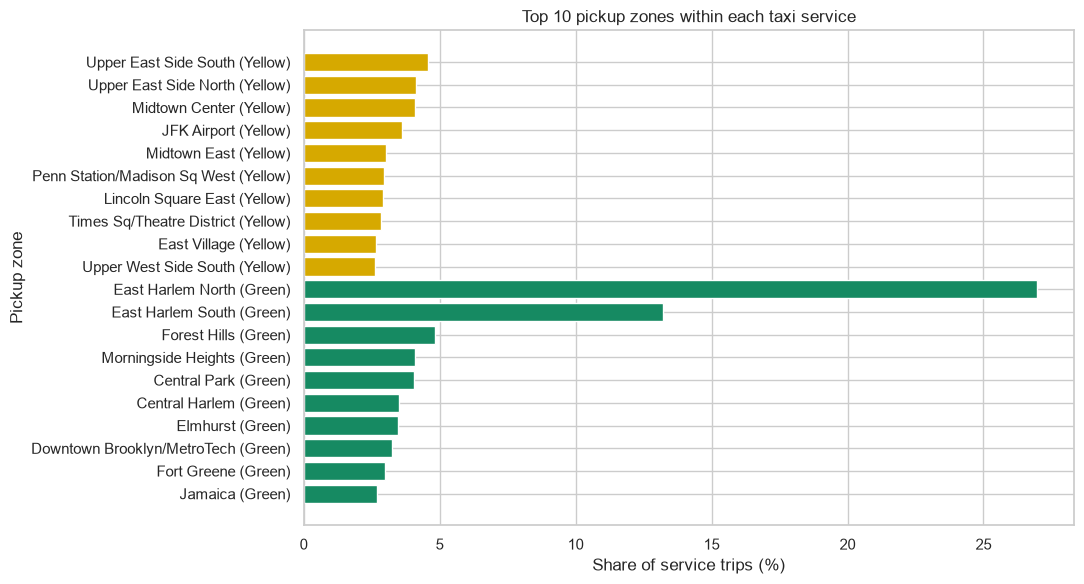

In [12]:
fig, ax = plt.subplots(figsize=(11, 6))
zone_plot = top_zones.copy()
zone_plot["label"] = zone_plot["zone"] + " (" + zone_plot["taxi_type"].str.title() + ")"
zone_plot = zone_plot.sort_values("trips")
ax.barh(zone_plot.label, zone_plot.service_share_pct, color=[COLORS[t] for t in zone_plot.taxi_type])
ax.set(title="Top 10 pickup zones within each taxi service", xlabel="Share of service trips (%)", ylabel="Pickup zone")
fig.tight_layout()
fig.savefig(FIGURES / "eda_top_pickup_zones.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. Key findings and implications

The findings below summarize the cleaned January to June 2026 records after applying the documented timestamp, source-month, duration, and location rules.

### Key findings

- **Substantial service imbalance:** The cleaned dataset contains **22,173,427 Yellow trips** and **243,529 Green trips**, a ratio of approximately **91 to 1**. Aggregate metrics would primarily describe Yellow performance. Report results separately by service.
- **Similar medians with a long upper tail:** Median duration is **14.1 minutes for Yellow** and **13.4 minutes for Green**. The 90th percentiles are **33.7** and **32.6 minutes**, respectively. Report robust and tail-sensitive metrics in addition to the mean.
- **Evening pickup peaks:** The highest-volume pickup hour is **18:00 for Yellow** and **17:00 for Green**. Within-service proportions are the appropriate basis for comparing these patterns.
- **Different pickup distributions:** Manhattan accounts for **86.8% of cleaned Yellow pickups** and **60.2% of Green pickups**. Report model performance by service and location to identify uneven coverage.
- **Passenger-count limitations:** Missing or zero counts occur in **26.44% of Yellow trips** and **15.87% of Green trips**. Treat this feature cautiously and explicitly handle missing values if it is used.

### Modeling implications

Pickup time, pickup and drop-off zones, borough, and taxi type are reasonable prediction-time features. The service imbalance and different geographic distributions support service-specific evaluation. The duration filter is an analytical choice and should be assessed with a sensitivity analysis.

These findings are descriptive, not causal. Historical zone-level TLC records do not contain live traffic, weather, road closures, or exact route distance. The analysis supports a historical duration model, not a live navigation estimate.


## 9. Prediction-time feature screening

This section estimates which information available at trip start helps predict duration. It uses January to April for fitting and May for validation. June is not loaded or used here, preserving it for final evaluation. The screening model is exploratory and does not replace comparison of the planned models.

A fixed-seed sample of up to 300,000 Yellow training trips is combined with all eligible Green training trips. May validation is capped at 100,000 Yellow trips and retains eligible Green trips. This deliberate Green oversampling makes its patterns more visible than in the real fleet mix. Metrics are reported by service, and importance is screening evidence rather than a production-population ranking.

The reusable scikit-learn pipeline derives cyclic pickup-time features and encodes location zones, service, and passenger count. Imputation and encoding are fitted on January to April only. Importance is measured by permuting each raw input column on May and recording the increase in MAE, grouping all engineered representations of pickup time. No post-trip fields, target-derived route statistics, or June rows are used. Route median duration is deferred until train-only fitting and robust fallbacks are implemented.


,split,taxi_type,rows,first_pickup,last_pickup
0,train,yellow,300000,2026-01-01 00:00:14,2026-04-30 23:59:59
1,train,green,158756,2026-01-01 00:03:27,2026-04-30 23:54:33
2,validation,yellow,100000,2026-05-01 00:00:03,2026-05-31 23:58:06
3,validation,green,42677,2026-05-01 00:02:02,2026-05-31 23:59:13


,taxi_type,validation_rows,baseline_median_mae_min,pipeline_mae_min,pipeline_rmse_min,pipeline_median_ae_min,pipeline_r2
0,yellow,100000,10.053,8.440,12.908,6.317,0.300
1,green,42677,8.705,7.444,11.866,4.911,0.302


,input_feature,mae_increase_min,importance_std_min
2,PULocationID,1.538,0.004
3,DOLocationID,1.027,0.005
4,passenger_count,0.712,0.013
1,pickup_datetime,0.596,0.004
0,taxi_type,0.522,0.006


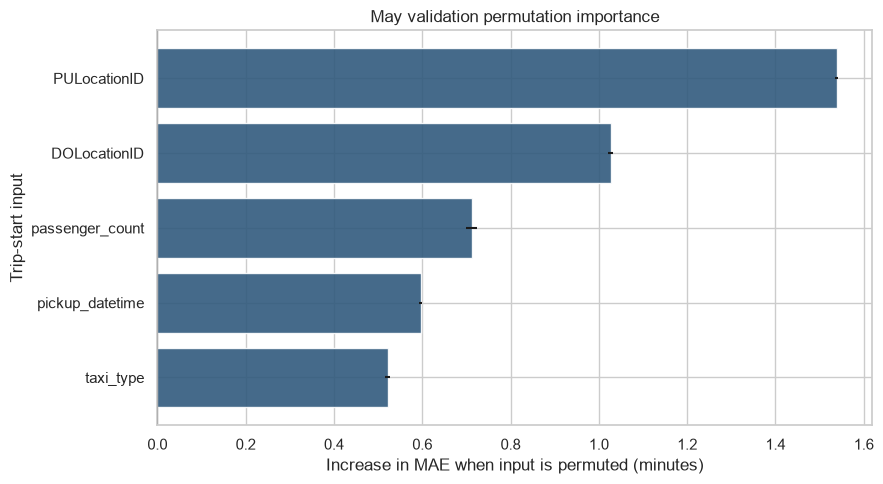

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

FEATURE_SCREEN_SEED = 33
YELLOW_TRAIN_CAP = 300_000
YELLOW_VALIDATION_CAP = 100_000

def load_time_split_sample(service, months, cap):
    source = PROCESSED / f"{service}_cleaned_2026H1.parquet"
    if not source.exists():
        raise FileNotFoundError(f"Expected {source}. Run the cleaning section first.")
    month_list = ', '.join(str(int(month)) for month in months)
    limit_sql = ""
    if cap is not None:
        limit_sql = f"ORDER BY hash(pickup_datetime, PULocationID, DOLocationID, {FEATURE_SCREEN_SEED}) LIMIT {int(cap)}"
    return con.execute(
        f"""SELECT taxi_type, pickup_datetime, trip_duration_minutes, PULocationID, DOLocationID, passenger_count
             FROM read_parquet('{sql_path(source)}') WHERE month IN ({month_list}) {limit_sql}"""
    ).df()

train_yellow = load_time_split_sample("yellow", (1, 2, 3, 4), YELLOW_TRAIN_CAP)
train_green = load_time_split_sample("green", (1, 2, 3, 4), None)
valid_yellow = load_time_split_sample("yellow", (5,), YELLOW_VALIDATION_CAP)
valid_green = load_time_split_sample("green", (5,), None)
train_screen = pd.concat([train_yellow, train_green], ignore_index=True)
valid_screen = pd.concat([valid_yellow, valid_green], ignore_index=True)
X_train_screen = train_screen.drop(columns="trip_duration_minutes")
y_train_screen = train_screen["trip_duration_minutes"]
X_valid_screen = valid_screen.drop(columns="trip_duration_minutes")
y_valid_screen = valid_screen["trip_duration_minutes"]

screening_sample_audit = pd.DataFrame([
    {"split": split_name, "taxi_type": service, "rows": len(frame),
     "first_pickup": frame.pickup_datetime.min(), "last_pickup": frame.pickup_datetime.max()}
    for split_name, frames in (("train", (train_yellow, train_green)), ("validation", (valid_yellow, valid_green)))
    for service, frame in zip(("yellow", "green"), frames)
])
display(screening_sample_audit)

def make_prediction_features(frame):
    pickup = pd.to_datetime(frame["pickup_datetime"])
    hour = pickup.dt.hour + pickup.dt.minute / 60
    weekday_value = pickup.dt.day_of_week
    return pd.DataFrame({
        "pickup_hour_sin": np.sin(2 * np.pi * hour / 24),
        "pickup_hour_cos": np.cos(2 * np.pi * hour / 24),
        "weekday_sin": np.sin(2 * np.pi * weekday_value / 7),
        "weekday_cos": np.cos(2 * np.pi * weekday_value / 7),
        "month": pickup.dt.month.astype("int8"),
        "is_weekend": (weekday_value >= 5).astype("int8"),
        "is_rush_hour": (((hour >= 7) & (hour < 10)) | ((hour >= 16) & (hour < 20))).astype("int8"),
        "PULocationID": frame["PULocationID"].astype("string"),
        "DOLocationID": frame["DOLocationID"].astype("string"),
        "passenger_count": pd.to_numeric(frame["passenger_count"], errors="coerce"),
        "taxi_type": frame["taxi_type"].astype("string"),
    }, index=frame.index)

numeric_features = ["pickup_hour_sin", "pickup_hour_cos", "weekday_sin", "weekday_cos", "month", "is_weekend", "is_rush_hour", "passenger_count"]
categorical_features = ["PULocationID", "DOLocationID", "taxi_type"]
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=True)),
    ]), categorical_features),
], remainder="drop")
feature_screen_pipeline = Pipeline([
    ("features", FunctionTransformer(make_prediction_features, validate=False)),
    ("preprocess", preprocessor),
    ("model", RandomForestRegressor(n_estimators=80, max_depth=18, min_samples_leaf=10,
                                      max_features=0.7, n_jobs=-1, random_state=FEATURE_SCREEN_SEED)),
])

training_median = float(y_train_screen.median())
feature_screen_pipeline.fit(X_train_screen, y_train_screen)
valid_pred_screen = feature_screen_pipeline.predict(X_valid_screen)
screening_metrics = []
for service in ("yellow", "green"):
    positions = valid_screen.taxi_type.eq(service).to_numpy()
    actual = y_valid_screen.to_numpy()[positions]
    predicted = valid_pred_screen[positions]
    screening_metrics.append({
        "taxi_type": service, "validation_rows": len(actual),
        "baseline_median_mae_min": mean_absolute_error(actual, np.full(len(actual), training_median)),
        "pipeline_mae_min": mean_absolute_error(actual, predicted),
        "pipeline_rmse_min": mean_squared_error(actual, predicted) ** 0.5,
        "pipeline_median_ae_min": median_absolute_error(actual, predicted),
        "pipeline_r2": r2_score(actual, predicted),
    })
screening_metrics = pd.DataFrame(screening_metrics)
display(screening_metrics.round(3))

permutation = permutation_importance(
    feature_screen_pipeline, X_valid_screen, y_valid_screen, scoring="neg_mean_absolute_error",
    n_repeats=3, random_state=FEATURE_SCREEN_SEED, n_jobs=-1,
)
feature_importance = pd.DataFrame({
    "input_feature": X_valid_screen.columns,
    "mae_increase_min": permutation.importances_mean,
    "importance_std_min": permutation.importances_std,
}).sort_values("mae_increase_min", ascending=False)
display(feature_importance.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
plot_data = feature_importance.sort_values("mae_increase_min")
ax.barh(plot_data.input_feature, plot_data.mae_increase_min, xerr=plot_data.importance_std_min, color="#315A7D", alpha=0.9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="May validation permutation importance", xlabel="Increase in MAE when input is permuted (minutes)", ylabel="Trip-start input")
fig.tight_layout()
fig.savefig(FIGURES / "eda_feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()


### Preliminary findings

On the sampled May validation data, pickup zone had the largest permutation importance: permuting it increased MAE by **1.536 minutes** on average. Drop-off zone followed (**1.026 minutes**), then passenger count (**0.714 minutes**), pickup time (**0.594 minutes**), and taxi type (**0.523 minutes**). The small repeat-to-repeat standard deviations show stable rankings within this sample and model, not certainty across other samples or algorithms.

The pipeline improved on the training-median baseline for both services. Yellow MAE was **8.440 minutes** versus **10.053 minutes** for the baseline; Green MAE was **7.445 minutes** versus **8.705 minutes**. R-squared was approximately **0.30** for each service, so substantial trip-level variation remains unexplained by the available trip-start inputs. These are screening results, not June test results.

### Interpretation and safeguards

Permutation importance is model- and sample-dependent. A large increase in MAE indicates that the fitted screening model relied on that input in this May sample. Correlated predictors can share or mask importance, and a small or negative value does not establish that a variable has no predictive value. The sampling design intentionally upweights Green relative to the full fleet; inspect service-level metrics and repeat the ranking under the final experiment design before drawing conclusions.

Use the ranking to prioritize features for the modeling notebook, not to claim causal influence. Zone-centroid distance is not included because the shapefile is not currently present in the project data. Actual trip distance, fare fields, drop-off time, and route statistics calculated from validation or test targets remain excluded. June must remain untouched until model and feature choices are finalized.

## 10. Scope, limitations, and outputs

- **Population imbalance:** Report service-level metrics so Yellow volume does not obscure Green performance.
- **Target definition:** Document the 1 to 180 minute inclusion rule and assess how alternative thresholds affect conclusions.
- **Feature availability:** Pickup time, location zones, and taxi type are available at trip start. Descriptive patterns do not establish causal effects.
- **Input quality:** Passenger-count missingness and zeros require explicit treatment if the feature is used.
- **Operational scope:** Zone-level historical records do not provide live traffic or exact routing inputs. Do not interpret these results as production navigation ETAs.

### Outputs

Cleaned Parquet datasets are saved in `data/processed/`. Figures are saved in `outputs/figures/`. Run the notebook cells in order to reproduce the analysis from `data/raw/`.
